# Problem Set 1
### Cheaper food, better nutrition? Evaluating a staple-food subsidy
#### Group: Jose Eduardo Campos Hernandez, Drishti Khemlani, Madeleine Roberts

##### Data import and cleaning

In [50]:
install.packages(c("tidyverse", "gt", "fixest"))
# Import packages
library(tidyverse)
library(gt)
library(fixest)

# Import data
staple_households <- read_csv("staple_households.csv", show_col_types = FALSE)
food_energy <- read_csv("food_energy.csv", show_col_types = FALSE)

# Clean data for analysis
raw_data <- staple_households |>
  pivot_longer(
    cols = c(rice_g, fish_g, vegetables_g, oil_g,
             rice_price_kg, fish_price_kg, vegetables_price_kg, oil_price_kg),
    names_to  = "variable",
    values_to = "value") |>
  mutate(food = str_remove(variable, "_g$|_price_kg$"),
         measure = if_else(str_ends(variable, "_g"), "grams_consumed", "price_kg")) |>
  select(-variable) |>
  pivot_wider(names_from = measure, values_from = value) |> 
  left_join(food_energy, by = "food") |> 
    transmute(household_id, 
              region, 
              treated, 
              wave, 
              baseline_resources, 
              cash_resources,
              food_spending, 
              other_spending, 
              subsidy_cost, 
              food, 
              price_g = price_kg/1000, 
              kcal_per_g,
              grams_consumed,
              food_caloric_intake = grams_consumed*kcal_per_g,
              food_share_spending = (grams_consumed*price_g)/food_spending*100)


The downloaded binary packages are in
	/var/folders/xf/2_bxtr3x5b598ypvvvs4k00h0000gn/T//RtmpixMmBI/downloaded_packages


##### **Question 1: Understand the data and make a prediction**
##### *Before calculating policy effects, record your prediction about how households will respond to cheaper rice and whether calorie intake will increase. State the reasoning and assumptions behind your prediction.*

**Answer:**

We predict that the 25% rice subsidy will initially encourage greater rice consumption through the substitution effect, as rice becomes relatively cheaper than other goods. However, the increase in real purchasing power introduces an income effect, whose direction depends on whether rice is a normal or inferior good. If rice is inferior, the income effect may partially or fully offset the substitution effect. Consequently, the overall effect on rice consumption is theoretically ambiguous.

We tentatively hypothesise that the subsidy will increase total calorie intake, although households may reallocate expenditure towards other foods or non-food consumption. We therefore expect the intervention to affect not only rice demand but potentially the composition of household consumption.

Our empirical analysis will evaluate whether the subsidy changes rice consumption, total calorie intake and the allocation of expenditure across goods.

##### *Explore and audit the dataset. What do you need to check before trusting an analysis of this pilot? Give a concise account of the sample, the policy as implemented and any data issues. Construct a measure of the policy’s stated outcome, explaining its units and any transformations you make.*

**Answer:**

The dataset contains 480 households across two regions, A and B, observed over three survey waves (Before, During and After), resulting in 1,440 household-wave observations. Within each region, 120 households were assigned to treatment and 120 to control, giving a total of 240 households in each group.

In [51]:
  # Sample structure
staple_households |>
  summarise(
    observations = n(),
    households = n_distinct(household_id),
    missing_values = sum(is.na(as.matrix(staple_households)))
  )

# Treatment allocation by region
staple_households |>
  distinct(household_id, region, treated) |>
  count(region, treated)

# Number of waves per household
staple_households |>
  count(household_id) |>
  count(n)

# Duplicate household-wave observations
staple_households |>
  count(household_id, wave) |>
  filter(n != 1)

# Check whether region and treatment stay constant
staple_households |>
  group_by(household_id) |>
  summarise(
    n_regions = n_distinct(region),
    n_treatment_values = n_distinct(treated),
    .groups = "drop"
  ) |>
  filter(n_regions != 1 | n_treatment_values != 1)

  # Check budget consistency and negative values
staple_households |>
  summarise(
    budget_violations = sum(
      abs(food_spending + other_spending - cash_resources) > 1e-6
    ),
    negative_food_quantities = sum(
      if_any(
        c(rice_g, fish_g, vegetables_g, oil_g),
        ~ .x < 0
      )
    ),
    negative_spending = sum(
      food_spending < 0 | other_spending < 0
    )
  )

observations,households,missing_values
<int>,<int>,<int>
1440,480,0


region,treated,n
<chr>,<dbl>,<int>
A,0,120
A,1,120
B,0,120
B,1,120


Storing counts in `nn`, as `n` already present in input
i Use `name = "new_name"` to pick a new name.


n,nn
<int>,<int>
3,480


household_id,wave,n
<chr>,<chr>,<int>


household_id,n_regions,n_treatment_values
<chr>,<int>,<int>


budget_violations,negative_food_quantities,negative_spending
<int>,<int>,<int>
0,0,0


The data audit confirms that there are no missing values, duplicate household-wave observations or survey attrition. All 480 households are observed in all three survey waves, while regional classification and treatment assignment remain constant over time. Furthermore, no negative food consumption quantities or expenditure values are observed, and household spending satisfies the budget identity, with food spending plus other spending equalling available cash resources. These findings indicate that the dataset is structurally consistent with the intended experimental design and contains no issues identified by these checks.

In [52]:
# Check whether the rice subsidy was implemented correctly

raw_data |>
  filter(food == "rice") |>
  group_by(wave, treated) |>
  summarise(
    mean_rice_price = mean(price_g),
    .groups = "drop"
  ) |>
  arrange(wave, treated)

  raw_data |>
  filter(food != "rice") |>
  group_by(food, wave, treated) |>
  summarise(
    mean_price = mean(price_g),
    .groups = "drop"
  ) |>
  arrange(food, wave, treated)

wave,treated,mean_rice_price
<chr>,<dbl>,<dbl>
After,0,0.0024
After,1,0.0024
Before,0,0.0024
Before,1,0.0024
During,0,0.0024
During,1,0.0018


food,wave,treated,mean_price
<chr>,<chr>,<dbl>,<dbl>
fish,After,0,0.012
fish,After,1,0.012
fish,Before,0,0.012
fish,Before,1,0.012
fish,During,0,0.012
fish,During,1,0.012
oil,After,0,0.010
oil,After,1,0.010
oil,Before,0,0.010


**Policy implementation**

Before the intervention, both treatment and control households faced a rice price of 0.0024 per gram. During the intervention, the average rice price for treated households decreased to 0.0018 per gram, representing a 25% reduction, while the control price remained unchanged. After the intervention, rice prices returned to 0.0024 per gram for both groups.

The prices of fish, vegetables and oil remained constant across treatment groups and survey waves. These findings are consistent with the intended implementation of a temporary rice subsidy, with no corresponding changes in the prices of other foods.

**Introduction to baseline balance tests**

Before estimating the policy effects, we examine whether the treatment and control groups are comparable across relevant pre-treatment characteristics. Although random assignment ensures comparability in expectation, differences may arise by chance in a finite sample. Baseline balance tests allow us to assess observed comparability, but do not independently validate the randomisation procedure.

In [53]:
# Analysis to check randomisation
check_data <- raw_data |> 
  mutate(flag = if_else(treated == 1, "Treated", "Control")) |> 
  filter(wave == "Before") |>
  group_by(household_id) |> 
  mutate(total_caloric_intake = sum(food_caloric_intake)) |> 
  ungroup() |> 
  filter(food == "rice")

balance_total <-  check_data |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance_A <- check_data |> 
  filter(region == "A") |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance_B <- check_data |> 
  filter(region == "B") |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance <- bind_rows("Total"    = balance_total,
                     "Region A" = balance_A,
                     "Region B" = balance_B,
                     .id = "sample")

# Code for table
labels <- c(baseline_resources = "Baseline resources",
            food_spending      = "Food spending",
            other_spending     = "Other spending",
            total_caloric_intake = "Total calorie intake (kcal/person/day)",
            food_caloric_intake = "Calories from rice (kcal/person/day)",
            food_share_spending  = "Share of spending on rice (%)")

balance_wide <- balance |> 
  mutate(Variable   = unname(labels[name]),
         Treatment  = Treated,
         Comparison = Control,
         `T-stat`   = paste0(sprintf("%.2f", t_stat), signif)) |> 
  select(sample, Variable, Treatment, Comparison, `T-stat`) |> 
  pivot_wider(names_from  = sample,
              values_from = c(Treatment, Comparison, `T-stat`),
              names_glue  = "{sample}|{.value}") |> 
  select(Variable, starts_with("Total"), starts_with("Region A"), starts_with("Region B"))

tbl1 <- balance_wide |> 
  gt(rowname_col = "Variable") |> 
  tab_header(title = "Table 1: Covariate balance before treatment") |> 
  tab_spanner_delim(delim = "|") |> 
  fmt_number(columns = matches("Treatment|Comparison"), decimals = 2) |> 
  cols_align(align = "center") |> 
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |> 
  opt_row_striping() |> 
  tab_source_note("Welch two-sample t-statistics comparing treatment and control group means before the subsidy. * p < 0.10, ** p < 0.05, *** p < 0.01")

IRdisplay::display_html(as_raw_html(tbl1))

"Welch two-sample t-statistics comparing treatment and control group means before the subsidy. * p < 0.10, ** p < 0.05, *** p < 0.01"


Table 1 reports treatment and control group means for six baseline variables, together with Welch two-sample t-statistics. The differences in baseline resources, food spending, other spending, total calorie intake, rice calorie intake and rice expenditure share are small and statistically insignificant at conventional significance levels. This pattern also holds within Regions A and B. The findings are consistent with the randomised assignment, although statistically insignificant differences do not establish exact equality between groups.

Outcome variable construction

The primary outcome is total daily calorie intake per person, measured in kilocalories per person per day (kcal/person/day). For each household-wave observation, we multiply the quantity of rice, fish, vegetables and oil consumed (in grams per person per day) by their respective energy conversion factors of 3.6, 1.2, 0.3 and 9.0 kcal/g, and sum the resulting values. This measures total calorie intake across the four food categories rather than rice consumption alone.

In [54]:
calorie_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(
    total_calories = sum(food_caloric_intake),
    .groups = "drop"
  )

##### Question 2: Explore the data
*Before evaluating the policy, explore the main features of the data. Choose a small set of descriptive tables and figures that help you understand households’ consumption, resources and spending, and how these vary across the sample and over time. Describe the patterns you find most informative or surprising. What questions do they raise? How should these patterns inform your subsequent policy evaluation? Explain why you selected each table or figure.*

In [56]:
# Table 2: Descriptive statistics by wave and treatment group

descriptive_table <- staple_households |>
  left_join(
    calorie_data,
    by = c("household_id", "region", "treated", "wave")
  ) |>
  mutate(
    Group = if_else(treated == 1, "Treated", "Control"),
    wave = factor(wave, levels = c("Before", "During", "After"))
  ) |>
  group_by(wave, Group) |>
  summarise(
    N = n(),
    mean_resources = mean(cash_resources),
    mean_food_spending = mean(food_spending),
    mean_other_spending = mean(other_spending),
    mean_rice_g = mean(rice_g),
    mean_calories = mean(total_calories),
    .groups = "drop"
  ) |>
  arrange(wave, Group)

descriptive_table

wave,Group,N,mean_resources,mean_food_spending,mean_other_spending,mean_rice_g,mean_calories
<fct>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Before,Control,240,10.06,2.676545,7.383455,494.8025,2125.000
Before,Treated,240,10.11,2.685735,7.424265,497.7158,2133.443
During,Control,240,10.16,2.696604,7.463396,483.6862,2089.092
During,Treated,240,10.21,2.759811,7.450189,459.9746,2051.548
After,Control,240,10.06,2.684459,7.375541,496.9158,2131.554
After,Treated,240,10.11,2.675169,7.434831,499.2250,2136.325


**Interpretation of Table 2: Descriptive Statistics**

Table 2 presents average household resources, food and non-food expenditure, rice consumption and total calorie intake across treatment groups and survey waves. Each group contains 240 households per wave. These variables were selected to examine household purchasing power, expenditure allocation and nutritional outcomes before, during and after the intervention.

Before the subsidy, treatment and control households exhibited similar consumption and expenditure patterns. During the intervention, average rice consumption among treated households declined from 497.72 to 459.97 grams per person per day, while total calorie intake fell from 2,133.44 to 2,051.55 kcal per person per day. In comparison, control households experienced smaller declines in both variables. Interestingly, treated households' food expenditure increased from 2.69 to 2.76 currency units per person per day, despite their lower rice consumption and calorie intake.

Following the withdrawal of the subsidy, rice consumption and total calorie intake returned close to their baseline levels in both groups. These patterns raise the possibility that households adjusted their consumption bundles in response to changing relative prices, potentially reallocating expenditure towards other foods. However, these descriptive statistics cannot establish the underlying mechanism or the causal effect of the subsidy.

The observed differences motivate a subsequent evaluation comparing changes in outcomes between treated and control households, while examining whether changes in food composition help explain the observed patterns.

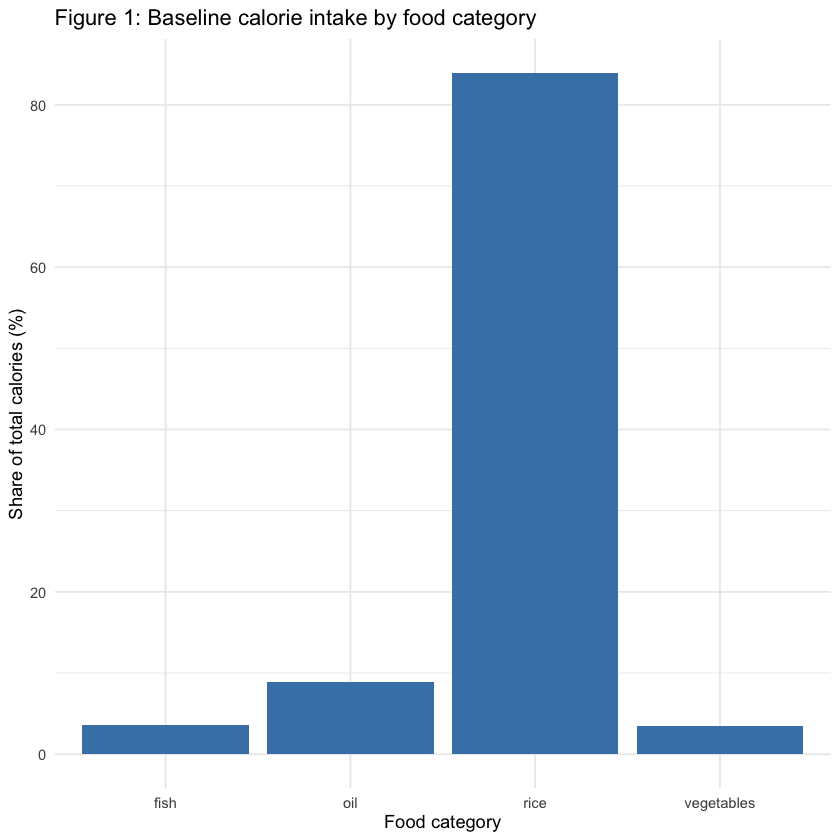

In [57]:
# Figure 1: Composition of calorie intake before the subsidy

food_composition <- raw_data |>
  filter(wave == "Before") |>
  group_by(food) |>
  summarise(
    mean_calories = mean(food_caloric_intake),
    .groups = "drop"
  ) |>
  mutate(
    calorie_share = 100 * mean_calories / sum(mean_calories)
  )

ggplot(
  food_composition,
  aes(x = food, y = calorie_share)
) +
  geom_col(fill = "steelblue") +
  labs(
    title = "Figure 1: Baseline calorie intake by food category",
    x = "Food category",
    y = "Share of total calories (%)"
  ) +
  theme_minimal()

**Interpretation of Figure 1**

Figure 1 illustrates the composition of average daily calorie intake before the intervention. Rice accounts for approximately 84% of total calories consumed, followed by oil, fish and vegetables, which contribute substantially smaller shares.

The predominance of rice suggests that household nutrition is highly dependent on staple-food consumption. Consequently, changes in rice demand may have a substantial influence on total calorie intake, making the rice subsidy particularly relevant to the government's nutritional objective.

However, the importance of rice in the baseline diet does not necessarily imply that a reduction in its price will increase calorie intake. Households may reallocate consumption towards other foods as their purchasing power increases. This raises the question of whether changes in dietary composition can offset changes in rice consumption, which will be investigated in the subsequent analysis.

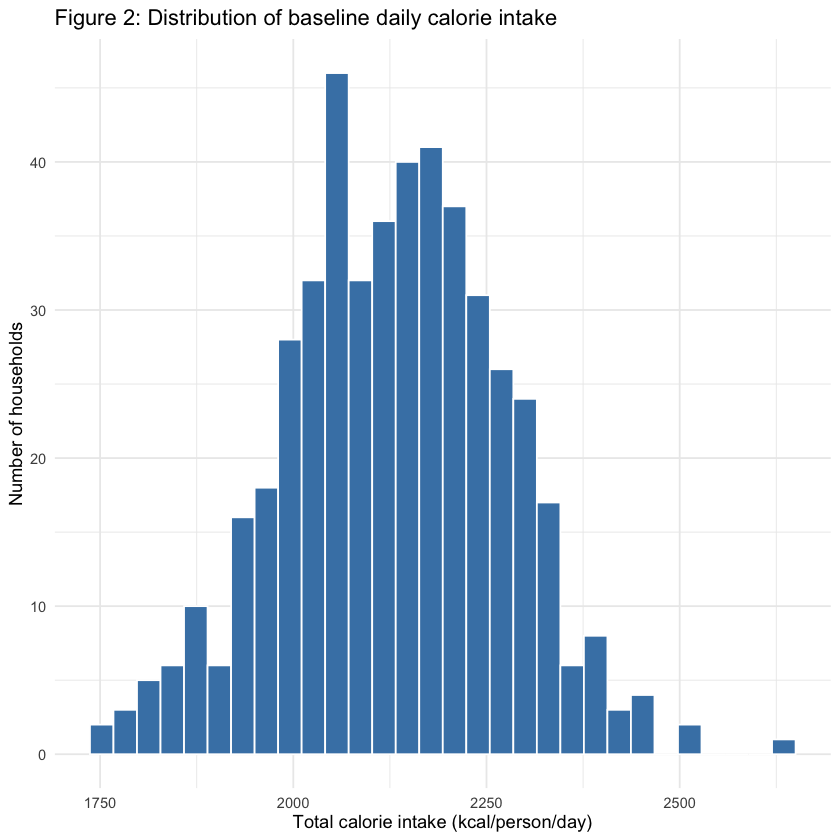

In [58]:
# Figure 2: Distribution of baseline calorie intake

calorie_data |>
  filter(wave == "Before") |>
  ggplot(aes(x = total_calories)) +
  geom_histogram(
    bins = 30,
    fill = "steelblue",
    colour = "white"
  ) +
  labs(
    title = "Figure 2: Distribution of baseline daily calorie intake",
    x = "Total calorie intake (kcal/person/day)",
    y = "Number of households"
  ) +
  theme_minimal()

**Interpretation of Figure 2**

Figure 2 presents the distribution of total daily calorie intake across the 480 households before the intervention. The distribution is approximately unimodal, with most households consuming between 2,000 and 2,300 kcal per person per day. However, calorie intake varies considerably, with observations ranging from approximately 1,750 to 2,650 kcal per person per day.

This variation suggests that average calorie intake may conceal meaningful differences in households' initial consumption levels. Consequently, the subsidy may have heterogeneous implications for households with relatively low versus high baseline calorie intake.

These findings motivate further investigation into whether the policy's effects differ according to initial household circumstances, rather than relying exclusively on an overall average treatment effect.

**Implications for the policy evaluation**

The descriptive analysis highlights three important features of the pilot. First, rice constitutes the dominant source of household calories, making changes in rice consumption particularly relevant to the policy's nutritional objective. Second, consumption and expenditure patterns vary across survey waves, with treated households exhibiting lower average rice consumption and calorie intake during the intervention. Third, baseline calorie intake differs across households, suggesting that average outcomes may conceal heterogeneity in responses.

These findings motivate an evaluation that compares changes in calorie intake between treatment and control households, accounts for common changes over time, and considers whether responses differ across household characteristics. However, the descriptive evidence alone cannot establish whether the subsidy caused the observed changes.

##### Question 3: Design a credible evaluation
*What comparison would allow you to assess whether the subsidy achieved its objective? Describe the outcome you will evaluate, the counterfactual you need and how the available data can help you approximate it. Explain why your comparison is informative about the policy rather than simply about differences between households or changes over time. State the assumptions your interpretation requires. Choose the tables or plots that would make your evaluation convincing to someone who has not seen the data.*

[MR comment]: I suggest we do a DiD (difference-in-differences) as our empirical strategy to compare changes in caloric intakes for treatment and control groups during and after. DiDs are good because the method exploits some naturally occurring events that change the treatment status of some units over time.

Necessary ingredients:
• Need an event that affects only a sub-population
• Observe the outcome of interest before and after the treatment
• Observe the outcome of interest for both treated and untreated groups

[MR comment]: I had a bit of help from old uni notes + LLM to put the equation together - the only part I'm not confident about is the choice of fixed effects to be region x time
$$Y_{it} = \alpha_i + \lambda_{r(i)t} + \beta_D\,(T_i \times \text{During}_t) + \beta_A\,(T_i \times \text{After}_t) + \varepsilon_{it}$$

where:

- $Y_{it}$ is the **total** calorie intake of household $i$ in wave $t$, in kcal per person per day, summed over rice, fish, vegetables and oil.
- $\alpha_i$ is a household fixed effect, which absorbs every household characteristic that does not change across waves.
- $\lambda_{r(i)t}$ is a region $\times$ wave fixed effect, which absorbs shocks common to all households in a region in a given wave. Randomisation was done within region, so this matches the design.
- $T_i = 1$ if household $i$ was randomly assigned to the subsidy, and $0$ otherwise.
- $\text{During}_t$ and $\text{After}_t$ are wave indicators. The Before wave is the omitted reference.
- Standard errors are clustered by household, because each household is observed three times.

Including region and time period fixed effects allow our comparison to be informative about the policy because we are controlling for differences between households and changes over time.


DiD ssumptions required:
Unobservables that affect the outcome do not vary differently in time between treated and control units. Without the treatment, the outcome of the treated control units would have changed by the same amount. The potential outcome (y0) or (y1) of the treated and control units change by the same amount between periods 0 and 1 = the Parallel Trends Assumption (PTA).

The PTA translates to:

• Unobservables that affect the outcome in average do not vary differently in
time between treated and control units

• Without the treatment, the average outcome of the treated and control units
would have changed by the same amount

Parallel trends holds by design in expectation, because randomisation makes the two groups the same in every way apart from the subsidy. Table 1 is our evidence.

##### Question 4: Assess the evidence
*Carry out your evaluation and report the direction and size of the estimated policy effect. How strong is the evidence for your conclusion? Address uncertainty in a way you can explain, taking account of how the observations were collected.*

*Decide whether a single overall result adequately describes the pilot. Investigate any differences in responses that you think matter for the policy decision, and justify your choices. Revisit your initial prediction: what did you learn, and what remains unresolved?*

Using consumption surveys gathered before, during, and after the subsidy was introduced, we find no evidence that the subsidy improved calorie intake for the pooled sample and infact might harm it --> we find decreased calorie intake, statistically significant treatment effect during. Considering the regions separately, we find that households in Region A especially reduce their intake of calories in response to the price subsidy. Effect goes away after subsidy ends.

[1] 1440

[1] 2111.16

OLS estimation, Dep. Var.: total_caloric_intake
Observations: 1,440
Fixed-effects: household_id: 480,  region^wave: 6
Standard-errors: Clustered (household_id) 
                     Estimate Std. Error   t value   Pr(>|t|)    
treated:wave_during -45.98725    9.86220 -4.662981 4.0475e-06 ***
treated:wave_after   -3.67313    9.19134 -0.399629 6.8961e-01    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
RMSE: 61.6     Adj. R2: 0.750873
             Within R2: 0.027912

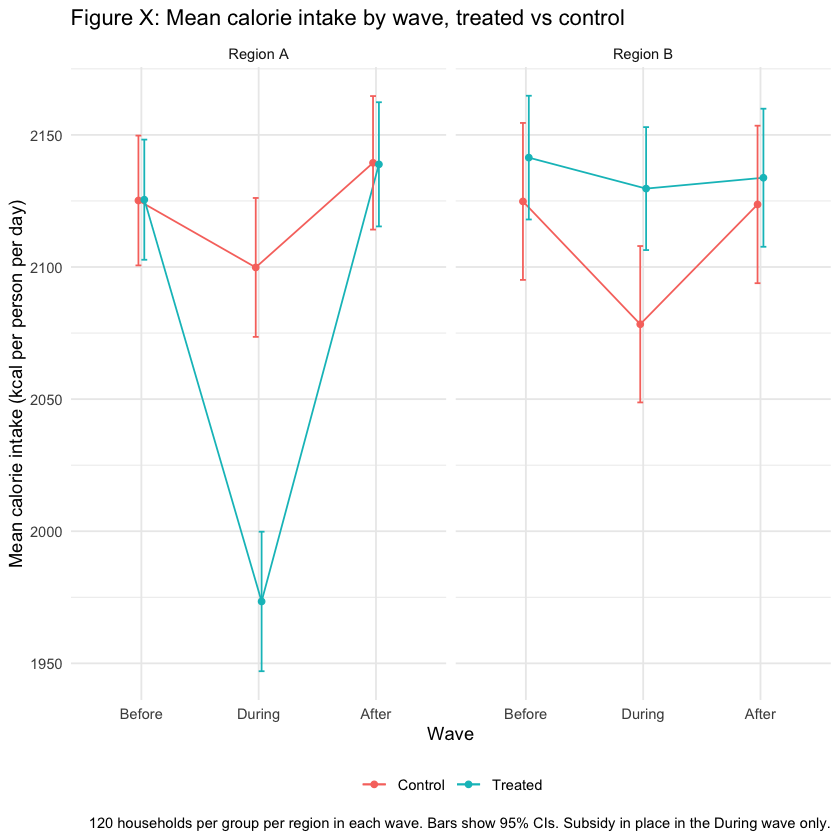

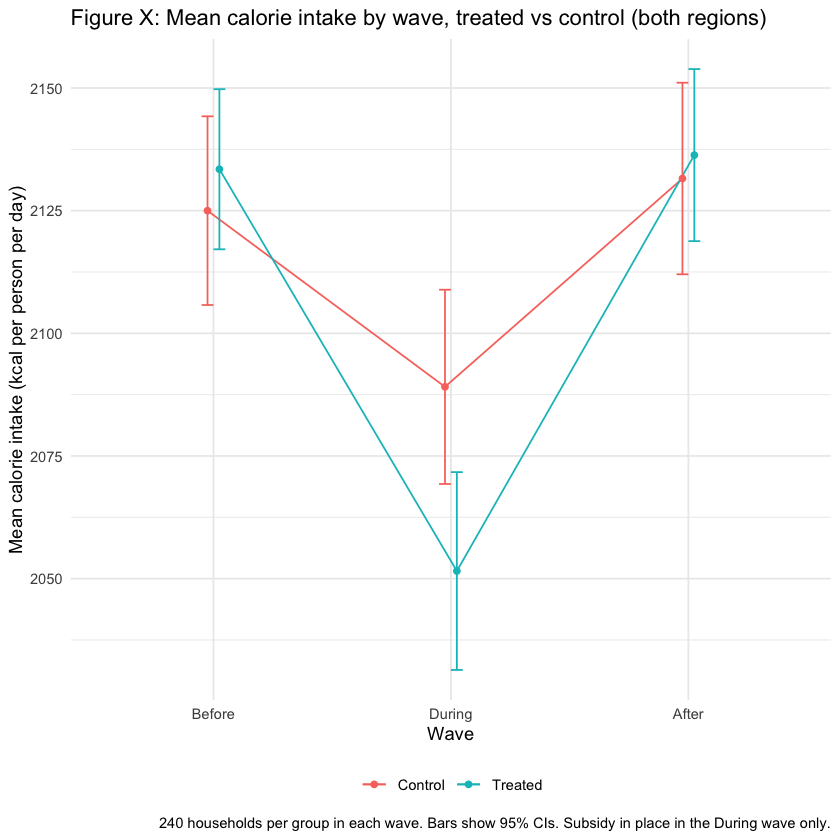

In [55]:
# not 100% sure about this code - only done DiDs in stata so needed LLM
regression_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(total_caloric_intake = sum(food_caloric_intake), .groups = "drop") |>
  mutate(wave = factor(wave, levels = c("Before", "During", "After")),
         wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"))

nrow(regression_data)                         
mean(regression_data$total_caloric_intake) 

did <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
               household_id + region^wave,
             data = regression_data, cluster = ~household_id)
summary(did)

regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(region, wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            n  = n(), .groups = "drop") |>
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +
  geom_line(position = position_dodge(0.1)) +
  geom_point(position = position_dodge(0.1)) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.1, position = position_dodge(0.1)) +
  facet_wrap(~ region, labeller = labeller(region = c(A = "Region A", B = "Region B"))) +
  labs(title = "Figure X: Mean calorie intake by wave, treated vs control",
       x = "Wave", y = "Mean calorie intake (kcal per person per day)", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Subsidy in place in the During wave only.") +
  theme_minimal() +
  theme(legend.position = "bottom")

  regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            n  = n(), .groups = "drop") |>
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +
  geom_line(position = position_dodge(0.1)) +
  geom_point(position = position_dodge(0.1)) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.1, position = position_dodge(0.1)) +
  labs(title = "Figure X: Mean calorie intake by wave, treated vs control (both regions)",
       x = "Wave", y = "Mean calorie intake (kcal per person per day)", colour = NULL,
       caption = "240 households per group in each wave. Bars show 95% CIs. Subsidy in place in the During wave only.") +
  theme_minimal() +
  theme(legend.position = "bottom")

##### Question 5: Develop an economic explanation
*How could households’ choices generate the pattern you found? Develop an explanation using the standard consumer choice problem. Specify the relevant goods, the budget constraint and the assumptions about preferences that your argument needs.*

*Use a clearly labelled budget-line and indifference-curve diagram to explain how the price change affects the chosen bundle. Discuss the roles of the substitution and income effects, and whether your explanation requires any goods to be normal or inferior. Connect the logic to your empirical findings. You do not need to estimate a utility function.*

[Useful set up for the question] from the paper - we can edit some of the wording:
Consider a simplified depiction of an impoverished consumer near a subsistence level of nutrition, whose diet consists of only two foods: a basic or staple good like rice, wheat, or maize and a ‘‘fancy’’ good like meat. The basic good offers a high level of calories at low cost, while the fancy good is preferred because of its taste but provides few calories per unit of currency. The poorest consumers will eat a lot of the staple in order to get enough calories and other nutrients to meet their basic needs, and they will use whatever money they have left over to purchase meat. As a result, consumers spend a high fraction of their budget on, and receive most of their nutrition from, the staple. By lowering the cost of the staple, subsidies free up substantial funds to be spent in other ways, that is, they induce large wealth effects. As households respond by substituting toward the types of goods that wealthier households consume, they may switch away from these nutritious staples, which are typically strongly inferior goods, and toward foods such as meat that offer more taste or add variety to the diet but are more costly sources of nutrients,2 or toward nonfood items. More generally, if consumers value the nonnutritional attributes of foods in addition to the nutritional attributes, the net nutritional consequences of a subsidy will depend on how consumers substitute among foods (as well as between food and nonfood items). If this substitution toward less nutritive foods is substantial enough, consumers may weaken or potentially even reverse the intended nutritional impact of the subsidies.

##### Question 6: Look for evidence of the mechanism
*Turn your explanation into predictions that you can investigate in the data. What patterns would strengthen it? What would cast doubt on it? Design and present the tables, plots or other comparisons that you judge most informative, and explain what each one establishes.*

*Consider at least one plausible alternative explanation and assess how far the available evidence distinguishes between the two. Be precise about the difference between describing a pattern and establishing why households chose it. Revise your explanation if your evidence calls for it, and identify any additional information you would need.*

[Helpful info from the paper]:
However, subsidizing goods on which households spend a high proportion of their budget can create large wealth effects. Consumers may then substitute toward foods with higher nonnutritional attributes (such as taste) but lower nutritional content per unit of currency, weakening or perhaps even reversing the subsidy’s intended impact.

##### Question 7: Brief the policymaker
*Write a 200–300 word briefing answering the government’s question: should it expand, revise or discontinue the programme? Ground your recommendation in your evidence and explain the main mechanism in plain language.*

*Does your verdict on the policy’s stated objective also determine whether households are better orworse off? Explain. Identify the most useful additional evidence or policy test before a final decision, and be clear about the limits of what this pilot establishes.*